In [ ]:
!pip install -q roboflow

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

from roboflow import Roboflow


In [ ]:
rf = Roboflow(api_key="F3JbmnW7UTb1F5n1xTE9")

In [ ]:
project = rf.workspace("michigans-workspace").project("skripsi-fjojc")

In [ ]:
version = project.version(1)

In [ ]:
dataset = version.download("folder")

In [ ]:
print(dataset.location)

In [ ]:
os.listdir(dataset.location)

In [ ]:
train_path = dataset.location + "/train"

os.listdir(train_path)


In [ ]:
import os

for folder in ['train','valid','test']:

    print(f"\n{folder.upper()}")

    path = os.path.join(dataset.location, folder)

    for kelas in os.listdir(path):

        jumlah = len(os.listdir(os.path.join(path, kelas)))

        print(kelas, ":", jumlah)

In [ ]:
import random
from PIL import Image

kelas = random.choice(os.listdir(train_path))

gambar = random.choice(os.listdir(os.path.join(train_path, kelas)))

img_path = os.path.join(train_path, kelas, gambar)

img = Image.open(img_path)

plt.figure(figsize=(5,5))
plt.imshow(img)
plt.title(kelas)
plt.axis("off")
plt.show()

In [ ]:
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import BatchNormalization
import matplotlib.pyplot as plt

import numpy as np

import os

In [ ]:
base_dir = dataset.location

train_dir = os.path.join(base_dir, "train")

valid_dir = os.path.join(base_dir, "valid")

test_dir = os.path.join(base_dir, "test")

In [ ]:
print(train_dir)
print(valid_dir)
print(test_dir)

In [ ]:
train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    rotation_range=15,

    width_shift_range=0.15,

    height_shift_range=0.15,

    zoom_range=0.15,

    shear_range=0.1,

    horizontal_flip=True,

    fill_mode='nearest'

)

In [ ]:
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [ ]:
train_generator = train_datagen.flow_from_directory(

    train_dir,

    target_size=(224,224),

    batch_size=32,

    class_mode='binary',

    shuffle=True

)

In [ ]:
valid_generator = test_datagen.flow_from_directory(

    valid_dir,

    target_size=(224,224),

    batch_size=32,

    class_mode='binary',

    shuffle=False

)

In [ ]:
test_generator = test_datagen.flow_from_directory(

    test_dir,

    target_size=(224,224),

    batch_size=32,

    class_mode='binary',

    shuffle=False

)

In [ ]:
print("Jumlah Data Training :", train_generator.samples)

print("Jumlah Data Validasi :", valid_generator.samples)

print("Jumlah Data Testing :", test_generator.samples)


In [ ]:
print(train_generator.class_indices)


In [ ]:
images, labels = next(train_generator)

plt.figure(figsize=(12,8))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.imshow(images[i])

    plt.title(labels[i])

    plt.axis("off")

plt.show()

# **Membangun Model ResNet50**

In [ ]:
from tensorflow.keras.applications import ResNet50

from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import BatchNormalization

from tensorflow.keras.models import Model

In [ ]:
base_model = ResNet50(

    weights='imagenet',

    include_top=False,

    input_shape=(224,224,3)

)

In [ ]:
# Freeze layer awal
for layer in base_model.layers[:-50]:
    layer.trainable = False

# Fine-tuning 50 layer terakhir
for layer in base_model.layers[-50:]:
    layer.trainable = True

In [ ]:
print("Jumlah layer :", len(base_model.layers))

trainable = sum([layer.trainable for layer in base_model.layers])

print("Layer yang dilatih :", trainable)

In [ ]:
x = base_model.output

In [ ]:
x = GlobalAveragePooling2D()(x)

In [ ]:
x = BatchNormalization()(x)

In [ ]:
x = Dense(

    512,

    activation='relu'

)(x)

In [ ]:
x = Dropout(0.5)(x)

In [ ]:
x = Dense(
    256,
    activation='relu'
)(x)

x = Dropout(0.3)(x)

predictions = Dense(
    1,
    activation='sigmoid'
)(x)

In [ ]:
model = Model(

    inputs=base_model.input,

    outputs=predictions

)

In [ ]:
model.summary()

In [ ]:
from tensorflow.keras.optimizers import Adam

optimizer = Adam(
    learning_rate=1e-5,
    amsgrad=True
)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.AUC(name='auc')
    ]
)

In [ ]:
print("Model berhasil dibuat.")

# **Training Model ResNet50**

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.callbacks import ReduceLROnPlateau

In [ ]:
early_stop = EarlyStopping(

    monitor='val_loss',

    patience=7,

    restore_best_weights=True,

    verbose=1

)

In [ ]:
checkpoint = ModelCheckpoint(

    "best_resnet50.keras",

    monitor="val_accuracy",

    save_best_only=True,

    save_weights_only=False,

    mode="max",

    verbose=1

)

In [ ]:
reduce_lr = ReduceLROnPlateau(

    monitor='val_loss',

    factor=0.2,

    patience=3,

    min_lr=1e-7,

    verbose=1
)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Label training
labels = train_generator.classes

# Hitung class weight
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels),
    y=labels
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

In [ ]:
history = model.fit(

    train_generator,

    validation_data=valid_generator,

    epochs=30,

    class_weight=class_weights,

    callbacks=[
        early_stop,
        checkpoint,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/30
1198/1198 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.6694 - auc: 0.7312 - loss: 0.6597 - precision: 0.6281 - recall: 0.6920
Epoch 1: val_accuracy improved from None to 0.84413, saving model to best_resnet50.keras

Epoch 1: finished saving model to best_resnet50.keras
1198/1198 ━━━━━━━━━━━━━━━━━━━━ 586s 462ms/step - accuracy: 0.7433 - auc: 0.8244 - loss: 0.5425 - precision: 0.7055 - recall: 0.7436 - val_accuracy: 0.8441 - val_auc: 0.9265 - val_loss: 0.3501 - val_precision: 0.8605 - val_recall: 0.7827 - learning_rate: 1.0000e-05
Epoch 2/30
1198/1198 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.8264 - auc: 0.9079 - loss: 0.3960 - precision: 0.8021 - recall: 0.8201
Epoch 2: val_accuracy improved from 0.84413 to 0.87348, saving model to best_resnet50.keras

Epoch 2: finished saving model to best_resnet50.keras
1198/1198 ━━━━━━━━━━━━━━━━━━━━ 529s 441ms/step - accuracy: 0.8382 - auc: 0.9190 - loss: 0.3721 - precision: 0.8130 - recall: 0.8346 - val_accuracy: 0.8735 - val_a

In [ ]:
print(history.history.keys())

dict_keys(['accuracy', 'auc', 'loss', 'precision', 'recall', 'val_accuracy', 'val_auc', 'val_loss', 'val_precision', 'val_recall', 'learning_rate'])


In [ ]:
model.save("resnet50_final.keras")

In [ ]:
import os

os.listdir()

['.config',
 'best_resnet50.keras',
 'Skripsi-1',
 'resnet50_final.keras',
 'sample_data']

In [ ]:
print(history.history['accuracy'][-1])

print(history.history['val_accuracy'][-1])

0.952823281288147
0.9096444249153137


# **Visualisasi Accuracy dan Loss**

In [ ]:
import matplotlib.pyplot as plt

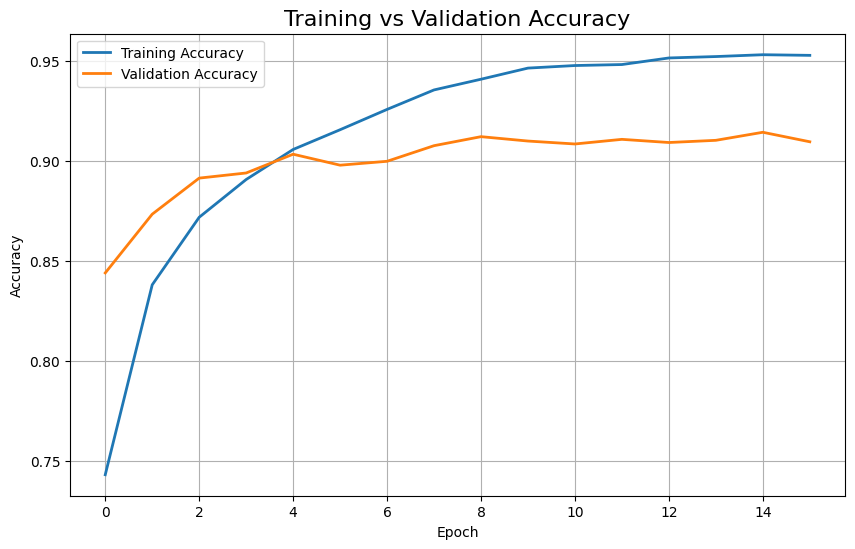

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy',
    linewidth=2
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy',
    linewidth=2
)

plt.title("Training vs Validation Accuracy", fontsize=16)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

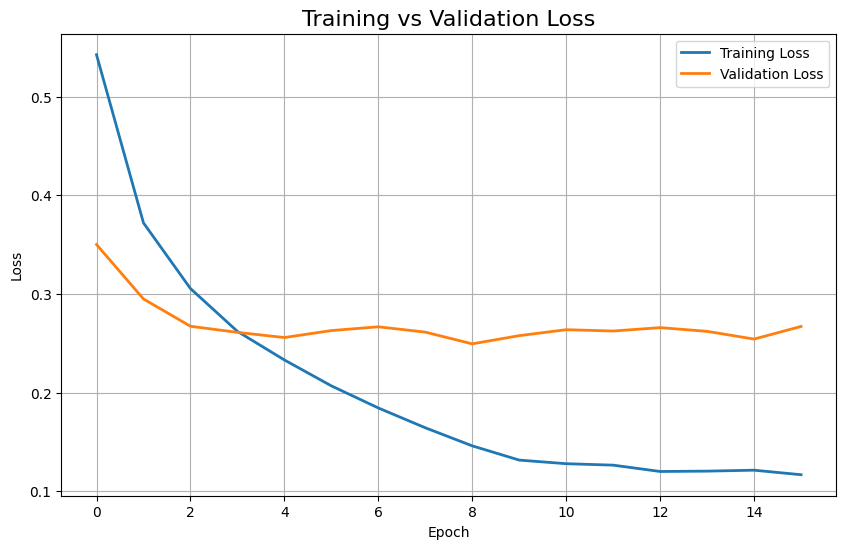

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    linewidth=2
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    linewidth=2
)

plt.title("Training vs Validation Loss", fontsize=16)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
best_epoch = history.history['val_accuracy'].index(
    max(history.history['val_accuracy'])
) + 1

print("Best Epoch :", best_epoch)

print("Training Accuracy :", history.history['accuracy'][best_epoch-1])

print("Validation Accuracy :", history.history['val_accuracy'][best_epoch-1])

print("Training Loss :", history.history['loss'][best_epoch-1])

print("Validation Loss :", history.history['val_loss'][best_epoch-1])

Best Epoch : 15
Training Accuracy : 0.9531364440917969
Validation Accuracy : 0.9143935441970825
Training Loss : 0.12143195420503616
Validation Loss : 0.254306823015213


In [ ]:
for i in range(len(history.history['accuracy'])):

    print(

        f"Epoch {i+1}"

        f" | Train Acc : {history.history['accuracy'][i]:.4f}"

        f" | Val Acc : {history.history['val_accuracy'][i]:.4f}"

        f" | Train Loss : {history.history['loss'][i]:.4f}"

        f" | Val Loss : {history.history['val_loss'][i]:.4f}"

    )

Epoch 1 | Train Acc : 0.7433 | Val Acc : 0.8441 | Train Loss : 0.5425 | Val Loss : 0.3501
Epoch 2 | Train Acc : 0.8382 | Val Acc : 0.8735 | Train Loss : 0.3721 | Val Loss : 0.2950
Epoch 3 | Train Acc : 0.8719 | Val Acc : 0.8915 | Train Loss : 0.3055 | Val Loss : 0.2673
Epoch 4 | Train Acc : 0.8908 | Val Acc : 0.8941 | Train Loss : 0.2621 | Val Loss : 0.2611
Epoch 5 | Train Acc : 0.9058 | Val Acc : 0.9034 | Train Loss : 0.2332 | Val Loss : 0.2559
Epoch 6 | Train Acc : 0.9157 | Val Acc : 0.8980 | Train Loss : 0.2069 | Val Loss : 0.2629
Epoch 7 | Train Acc : 0.9258 | Val Acc : 0.8999 | Train Loss : 0.1845 | Val Loss : 0.2668
Epoch 8 | Train Acc : 0.9355 | Val Acc : 0.9077 | Train Loss : 0.1644 | Val Loss : 0.2613
Epoch 9 | Train Acc : 0.9409 | Val Acc : 0.9122 | Train Loss : 0.1461 | Val Loss : 0.2495
Epoch 10 | Train Acc : 0.9465 | Val Acc : 0.9100 | Train Loss : 0.1317 | Val Loss : 0.2578
Epoch 11 | Train Acc : 0.9477 | Val Acc : 0.9085 | Train Loss : 0.1280 | Val Loss : 0.2638
Epoch 12

# **Prediksi Data Testing**

In [ ]:
# Pastikan urutan data test sesuai label
test_generator.reset()

# Prediksi probabilitas
y_pred_prob = model.predict(test_generator)

# Konversi ke label 0 dan 1
y_pred = (y_pred_prob > 0.5).astype(int).reshape(-1)

# Label asli
y_true = test_generator.classes

print("Jumlah Data Test :", len(y_true))

257/257 ━━━━━━━━━━━━━━━━━━━━ 33s 113ms/step
Jumlah Data Test : 8213


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [ ]:
import seaborn as sns

# **Confusion Matrix**

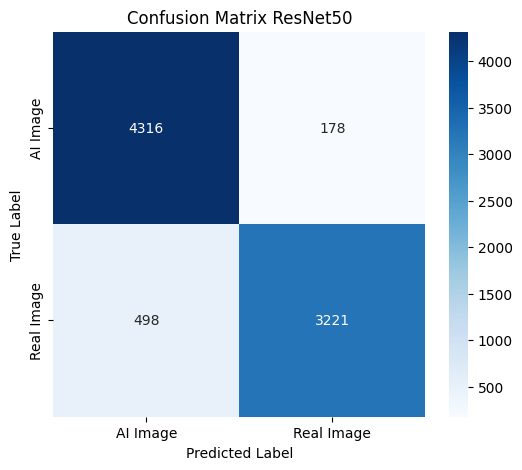

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['AI Image','Real Image'],
    yticklabels=['AI Image','Real Image']
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix ResNet50")

plt.show()

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# Nama kelas
class_names = ['AI Image', 'Real Image']

# Classification Report
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True
)

# Membuat tabel
hasil_per_kelas = pd.DataFrame({
    "Kelas": class_names,
    "Precision (%)": [
        report['AI Image']['precision'] * 100,
        report['Real Image']['precision'] * 100
    ],
    "Recall (%)": [
        report['AI Image']['recall'] * 100,
        report['Real Image']['recall'] * 100
    ],
    "F1-Score (%)": [
        report['AI Image']['f1-score'] * 100,
        report['Real Image']['f1-score'] * 100
    ]
})

# Dibulatkan 2 angka di belakang koma
hasil_per_kelas.iloc[:,1:] = hasil_per_kelas.iloc[:,1:].round(2)

hasil_per_kelas

,Kelas,Precision (%),Recall (%),F1-Score (%)
0,AI Image,89.66,96.04,92.74
1,Real Image,94.76,86.61,90.50


In [ ]:
hasil_per_kelas.insert(
    1,
    "Accuracy (%)",
    hasil_per_kelas["Recall (%)"]
)

hasil_per_kelas

,Kelas,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,AI Image,96.04,89.66,96.04,92.74
1,Real Image,86.61,94.76,86.61,90.50


# **Classification Report**

In [ ]:
print(classification_report(
    y_true,
    y_pred,
    target_names=['AI Image','Real Image']
))

              precision    recall  f1-score   support

    AI Image       0.90      0.96      0.93      4494
  Real Image       0.95      0.87      0.91      3719

    accuracy                           0.92      8213
   macro avg       0.92      0.91      0.92      8213
weighted avg       0.92      0.92      0.92      8213



# **Tabel Accuracy, Precision, Recall, F1-Score**

In [ ]:
import pandas as pd

In [ ]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

hasil = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1
    ]

})

hasil["Value"] = hasil["Value"].round(4)

print(hasil)

      Metric   Value
0   Accuracy  0.9177
1  Precision  0.9476
2     Recall  0.8661
3   F1-Score  0.9050


In [ ]:
display(hasil)

,Metric,Value
0,Accuracy,0.9177
1,Precision,0.9476
2,Recall,0.8661
3,F1-Score,0.9050


# **Grafik Accuracy Training vs Validation**

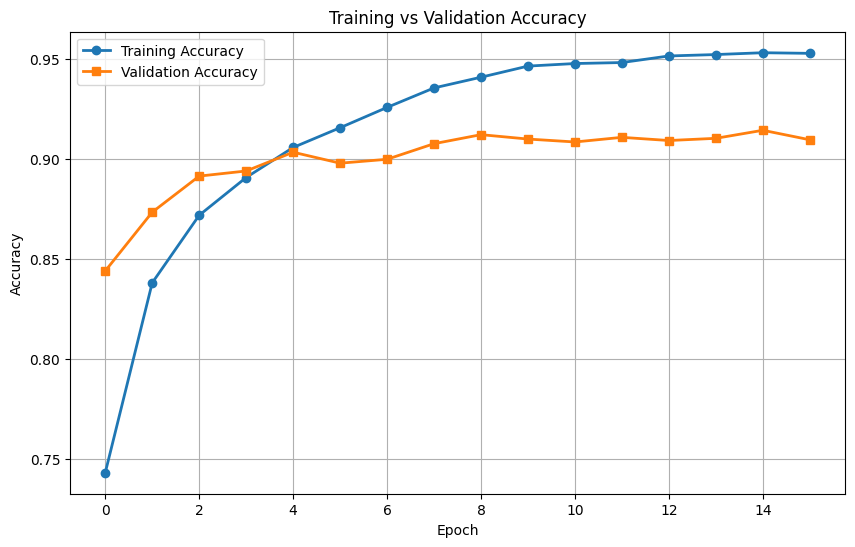

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    history.history['accuracy'],
    marker='o',
    linewidth=2,
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    marker='s',
    linewidth=2,
    label='Validation Accuracy'
)

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

# **Grafik Loss Training vs Validation**

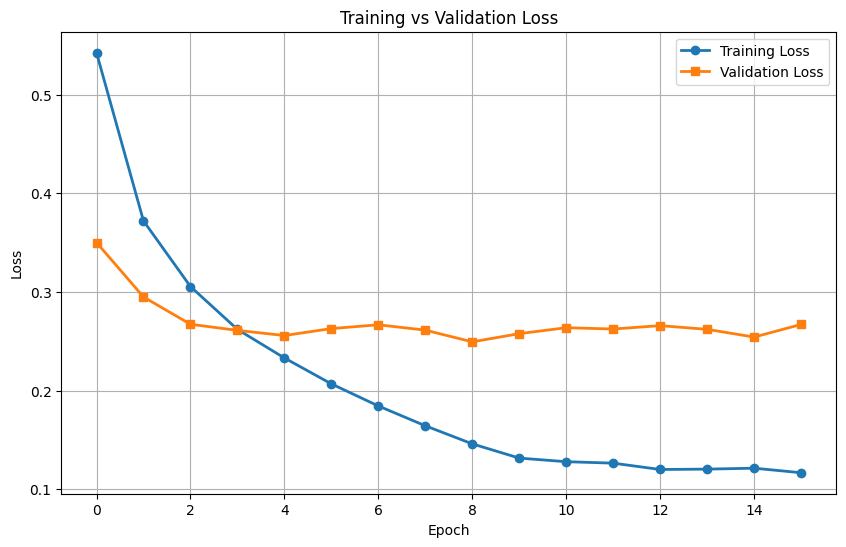

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(
    history.history['loss'],
    marker='o',
    linewidth=2,
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    marker='s',
    linewidth=2,
    label='Validation Loss'
)

plt.title("Training vs Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

# **Tabel History Semua Epoch**

In [ ]:
history_df = pd.DataFrame({

    "Epoch": range(1,len(history.history['accuracy'])+1),

    "Train Accuracy": history.history['accuracy'],

    "Validation Accuracy": history.history['val_accuracy'],

    "Train Loss": history.history['loss'],

    "Validation Loss": history.history['val_loss']

})

history_df = history_df.round(4)

display(history_df)

,Epoch,Train Accuracy,Validation Accuracy,Train Loss,Validation Loss
0,1,0.7433,0.8441,0.5425,0.3501
1,2,0.8382,0.8735,0.3721,0.2950
2,3,0.8719,0.8915,0.3055,0.2673
3,4,0.8908,0.8941,0.2621,0.2611
4,5,0.9058,0.9034,0.2332,0.2559
5,6,0.9157,0.8980,0.2069,0.2629
6,7,0.9258,0.8999,0.1845,0.2668
7,8,0.9355,0.9077,0.1644,0.2613
8,9,0.9409,0.9122,0.1461,0.2495
9,10,0.9465,0.9100,0.1317,0.2578


# **Menampilkan Nilai Terbaik**

In [ ]:
best_epoch = np.argmax(history.history['val_accuracy'])

print("="*40)
print("HASIL TERBAIK")
print("="*40)

print("Best Epoch :", best_epoch+1)

print("Training Accuracy :", round(history.history['accuracy'][best_epoch],4))
print("Validation Accuracy :", round(history.history['val_accuracy'][best_epoch],4))

print("Training Loss :", round(history.history['loss'][best_epoch],4))
print("Validation Loss :", round(history.history['val_loss'][best_epoch],4))

print("="*40)

HASIL TERBAIK
Best Epoch : 15
Training Accuracy : 0.9531
Validation Accuracy : 0.9144
Training Loss : 0.1214
Validation Loss : 0.2543


# **Tabel Evaluasi Final (Sangat Cocok untuk Skripsi)**

In [ ]:
evaluasi = pd.DataFrame({

    "Evaluasi":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],

    "Nilai":[
        accuracy,
        precision,
        recall,
        f1
    ]

})

evaluasi["Nilai"] = evaluasi["Nilai"].map(lambda x: f"{x*100:.2f}%")

display(evaluasi)

,Evaluasi,Nilai
0,Accuracy,91.77%
1,Precision,94.76%
2,Recall,86.61%
3,F1-Score,90.50%


# **GUI Gradio**

In [ ]:
!pip install -q gradio

In [ ]:
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import load_model

def predict_image(img):

    img = img.convert("RGB")
    img = img.resize((224,224))

    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    pred = model.predict(x, verbose=0)[0][0]

    ai_prob = float(1-pred)
    real_prob = float(pred)

    return {
        "Gambar AI": ai_prob,
        "Gambar Asli": real_prob
    }

In [ ]:
import gradio as gr

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="blue"
    ),
    title="Sistem Klasifikasi Gambar AI"
) as demo:

    gr.Markdown("""
    # 🤖 SISTEM KLASIFIKASI GAMBAR AI MENGGUNAKAN RESNET50

    ### Implementasi Model Deep Learning ResNet50

    Upload gambar kemudian klik **Prediksi**
    """)

    with gr.Row():

        input_img = gr.Image(
            type="pil",
            label="Upload Gambar",
            height=300,
            width=300
        )

        output = gr.Label(
            label="Hasil Prediksi"
        )

    with gr.Row():

        pred_btn = gr.Button(
            "🔍 Prediksi",
            variant="primary"
        )

        clear_btn = gr.ClearButton(
            value="🔄 Reset",
            components=[input_img, output]
        )

    gr.Markdown("---")

    pred_btn.click(
        fn=predict_image,
        inputs=input_img,
        outputs=output
    )

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.


In [ ]:
model = load_model("best_resnet50.keras")

print("Model berhasil dimuat")

Model berhasil dimuat


In [ ]:
demo.launch(
    debug=True,
    share=True
)

In [ ]:
print(train_generator.class_indices)

In [ ]:
print(train_generator.class_indices)

In [ ]:
import gradio as gr
print(gr.__version__)

In [ ]:
import os

print(train_generator.samples)
print(valid_generator.samples)
print(test_generator.samples)

print(train_generator.class_indices)

In [ ]:
pred = model.predict(x, verbose=0)[0][0]

print(pred)

In [ ]:
import os

print(os.listdir())

In [1]:
import os

print(os.listdir('/content'))


['.config', 'sample_data']


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os

print(os.listdir('/content/drive/MyDrive'))

['data_registras.pdf', 'AHMAD BAIHAQI.pdf', 'Bukti Pendaftaran (1).pdf', 'WhatsApp Video', 'WhatsApp Image', 'Database WhatsApp', 'Ikki', 'Zoom background', 'VID_59380216_210721_172..mp4', 'Aad & Resepsi', 'Bukit', 'Spreadsheet tanpa judul (1).gsheet', 'Spreadsheet tanpa judul.gsheet', 'Tugas 1 PBO-Ahmad Baihaqi-13020220337.pdf', 'IMG_20250624_160856.jpg', 'IMG_20250708_145120.jpg', 'Diagram Tanpa Judul', '28 Des 18.05\u200b.m4a', 'ikki S. Kom', 'Colab Notebooks', 'Berita Acara Proposal Baihaqi.pdf']


In [5]:
import os

print(os.listdir('/content/drive/MyDrive/Colab Notebooks'))

['Untitled0.ipynb', 'Untitled1.ipynb', 'Salinan dari Training Gambar ResNet50']


In [6]:
import os

path = '/content/drive/MyDrive/Colab Notebooks/Salinan dari Training Gambar ResNet50'

print("Apakah folder:", os.path.isdir(path))
print("Apakah file:", os.path.isfile(path))

Apakah folder: False
Apakah file: True


In [7]:
import os

path = '/content/drive/MyDrive/Colab Notebooks/Salinan dari Training Gambar ResNet50'

print(os.path.basename(path))

Salinan dari Training Gambar ResNet50


In [8]:
!cp "/content/drive/MyDrive/Colab Notebooks/Salinan dari Training Gambar ResNet50" \
"/content/Klasifikasi-Gambar-Asli-dan-Gambar-AI-Menggunakan-Arsitektur-CNN-ResNet-50/Training_Gambar_ResNet50.ipynb"

cp: cannot create regular file '/content/Klasifikasi-Gambar-Asli-dan-Gambar-AI-Menggunakan-Arsitektur-CNN-ResNet-50/Training_Gambar_ResNet50.ipynb': No such file or directory


In [9]:
!ls /content

drive  sample_data


In [10]:
!git clone "https://github.com/AhmadBaihaqii/Klasifikasi-Gambar-Asli-dan-Gambar-AI-Menggunakan-Arsitektur-CNN-ResNet-50.git"


Cloning into 'Klasifikasi-Gambar-Asli-dan-Gambar-AI-Menggunakan-Arsitektur-CNN-ResNet-50'...


In [11]:
!cp "/content/drive/MyDrive/Colab Notebooks/Salinan dari Training Gambar ResNet50" \
"/content/Klasifikasi-Gambar-Asli-dan-Gambar-AI-Menggunakan-Arsitektur-CNN-ResNet-50/Training_Gambar_ResNet50.ipynb"

In [12]:
!ls "/content/Klasifikasi-Gambar-Asli-dan-Gambar-AI-Menggunakan-Arsitektur-CNN-ResNet-50"

Training_Gambar_ResNet50.ipynb


In [13]:
%cd /content/Klasifikasi-Gambar-Asli-dan-Gambar-AI-Menggunakan-Arsitektur-CNN-ResNet-50

/content/Klasifikasi-Gambar-Asli-dan-Gambar-AI-Menggunakan-Arsitektur-CNN-ResNet-50


In [14]:
!git add .

In [15]:
!git commit -m "Menambahkan notebook training ResNet50"

Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@2e55dc7614f6.(none)')


In [16]:
!git config --global user.name "Ahmad Baihaqii"

In [17]:
!git config --global user.email "khybaihaqi@gmail.com"

In [18]:
!git config --global user.name
!git config --global user.email

Ahmad Baihaqii
khybaihaqi@gmail.com


In [19]:
!git add .

In [20]:
!git commit -m "Menambahkan notebook training ResNet50"

[main (root-commit) 23431f1] Menambahkan notebook training ResNet50
 1 file changed, 1 insertion(+)
 create mode 100644 Training_Gambar_ResNet50.ipynb


In [21]:
!git push origin main

fatal: could not read Username for 'https://github.com': No such device or address
